# Experiment 028: MC-SFT to GRPO analysis

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '028_1'
FIG.mkdir(parents=True, exist_ok=True)
TIERS = ('easy', 'medium', 'hard')
GROUPS = ('overall',) + TIERS

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def load_run(tag, prefix):
    path = RES / tag
    return {
        'path': path,
        'eval': jload(path / f'{prefix}_eval.json'),
        'probe': jload(path / f'{prefix}_logprob.json'),
        'preds': jsonl(path / f'{prefix}_preds.jsonl'),
        'probe_preds': jsonl(path / f'{prefix}_logprob_preds.jsonl'),
    }

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

RUNS = {
    'base -> GRPO': load_run('013_COLAB_FULL_B7_base_grpo_seed2', 'grpo'),
    'GSM8K-SFT -> GRPO': load_run('013_COLAB_FULL_B7_sft_grpo_seed2', 'grpo'),
    'MC-SFT': load_run('014_p8_COLAB_FULL_B7_sft_only_seed2', 'sft'),
    'MC-SFT -> GRPO': load_run('028_COLAB_FULL_B7_mcsft_grpo_seed2', 'grpo'),
}

plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))

figures -> analysis/figures/028_1


## Run outcomes

,outcome,step reached,last checkpoint,minutes,peak VRAM GiB,endpoint
seed,,,,,,
0,A2 sentinel,150,100,9.40,28.42,False
1,A2 sentinel,150,100,10.28,28.42,False
2,completed,500,500,22.70,31.07,True


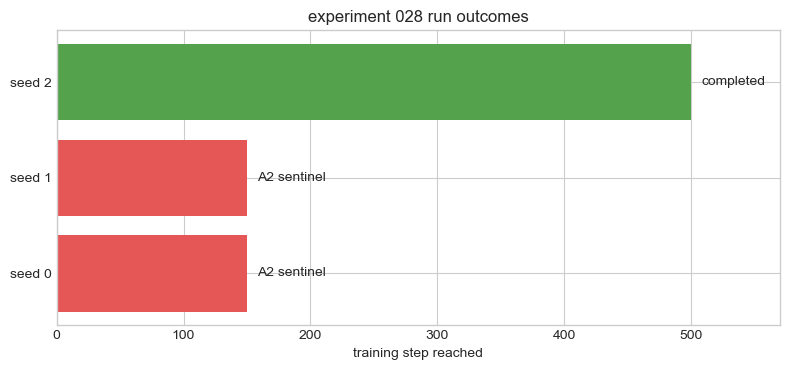

In [2]:
# show the registered outcome for each seed
status_rows = []
for seed in (0, 1, 2):
    path = RES / f'028_COLAB_FULL_B7_mcsft_grpo_seed{seed}'
    attempt = jload(path / 'arm_manifest.json')['attempts'][-1]
    stopped = 'sentinel abort' in (attempt.get('error_message') or '')
    status_rows.append({
        'seed': seed,
        'outcome': 'A2 sentinel' if stopped else 'completed',
        'step reached': 150 if stopped else attempt['end_step'],
        'last checkpoint': attempt['end_step'],
        'minutes': attempt['elapsed_sec'] / 60,
        'peak VRAM GiB': attempt['peak_vram_gib'],
        'endpoint': (path / 'arm_complete.json').exists(),
    })

status_tbl = pd.DataFrame(status_rows).set_index('seed')
display(status_tbl.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ['#E45756' if value == 'A2 sentinel' else '#54A24B' for value in status_tbl['outcome']]
bars = ax.barh([f'seed {seed}' for seed in status_tbl.index], status_tbl['step reached'], color=colors)
for bar, row in zip(bars, status_tbl.itertuples()):
    ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2, row.outcome, va='center')
ax.set_xlim(0, 570)
ax.set_xlabel('training step reached')
ax.set_title('experiment 028 run outcomes')
fig.tight_layout()
save(fig, 'fig01_run_outcomes')
plt.show()

## Seed 2 training

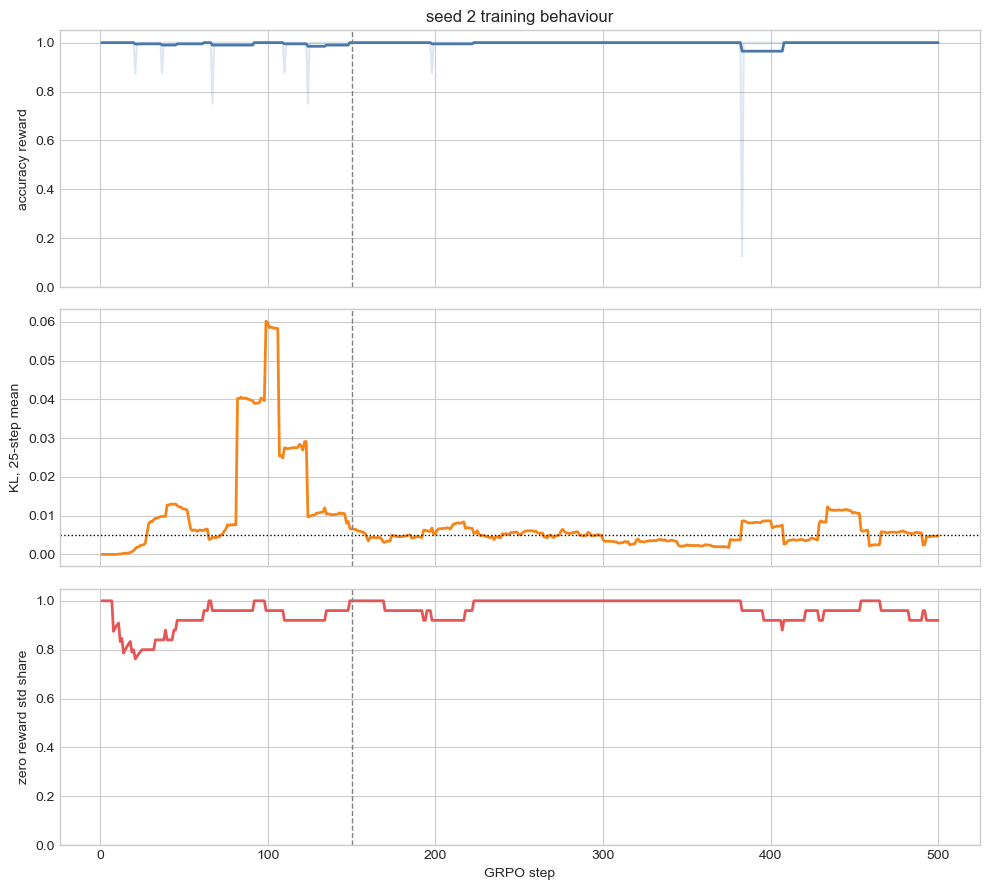

In [3]:
trainlog = jload(RES / '028_COLAB_FULL_B7_mcsft_grpo_seed2' / 'grpo_trainlog.json')
train = pd.DataFrame([row for row in trainlog if 'rewards/accuracy_reward/mean' in row])
smooth = train.set_index('step')[[
    'rewards/accuracy_reward/mean',
    'kl',
    'frac_reward_zero_std',
]].rolling(25, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(train['step'], train['rewards/accuracy_reward/mean'], color='#4C78A8', alpha=0.18)
axes[0].plot(smooth.index, smooth['rewards/accuracy_reward/mean'], color='#4C78A8', lw=2)
axes[0].set_ylabel('accuracy reward')
axes[0].set_ylim(0, 1.05)

axes[1].plot(smooth.index, smooth['kl'], color='#F58518', lw=2)
axes[1].axhline(0.005, color='black', ls=':', lw=1)
axes[1].set_ylabel('KL, 25-step mean')

axes[2].plot(smooth.index, smooth['frac_reward_zero_std'], color='#E45756', lw=2)
axes[2].set_ylabel('zero reward std share')
axes[2].set_xlabel('GRPO step')
axes[2].set_ylim(0, 1.05)

for ax in axes:
    ax.axvline(150, color='grey', ls='--', lw=1)
axes[0].set_title('seed 2 training behaviour')
fig.tight_layout()
save(fig, 'fig02_seed2_training')
plt.show()

## Seed 2 endpoint

group                         overall    easy  medium    hard
recipe            metric                                     
GSM8K-SFT -> GRPO generative   0.8068  0.8862  0.7980  0.6439
                  probe        0.7956  0.8976  0.8062  0.5530
MC-SFT            generative   0.7845  0.8908  0.7783  0.5581
                  probe        0.7999  0.8976  0.8095  0.5682
MC-SFT -> GRPO    generative   0.7829  0.8874  0.7783  0.5581
                  probe        0.7999  0.8999  0.8079  0.5657
base -> GRPO      generative   0.7771  0.8646  0.7570  0.6136
                  probe        0.8025  0.8987  0.8112  0.5758

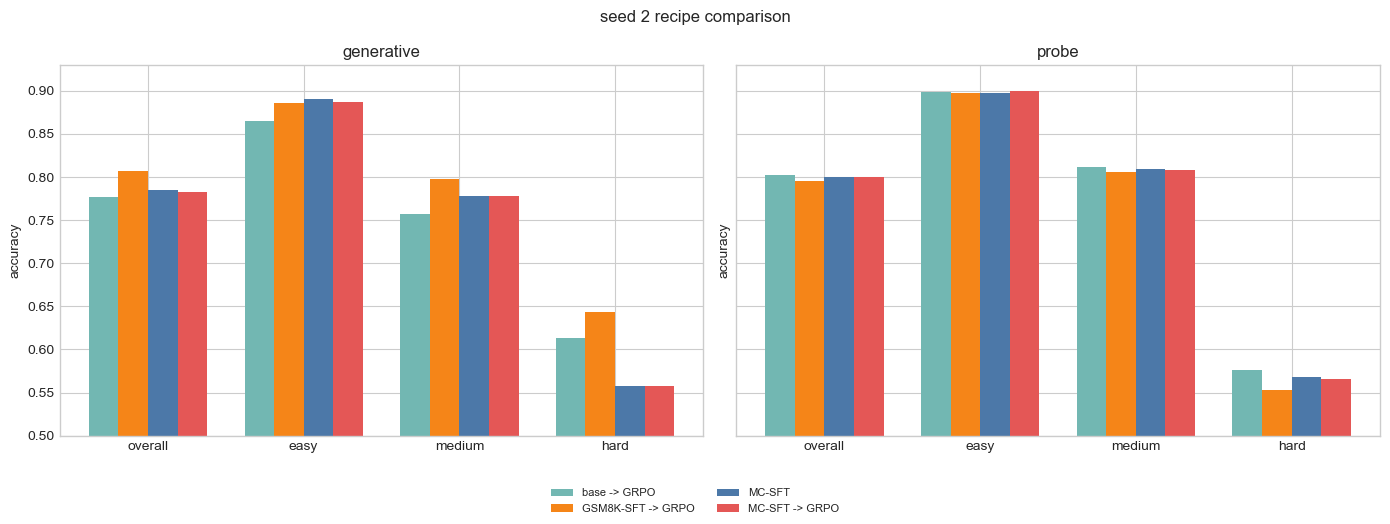

Only seed 2 has a completed experiment 028 endpoint.


In [4]:
endpoint_rows = []
for recipe, run in RUNS.items():
    for metric, values, rows in [
        ('generative', run['eval']['per_tier_acc'], run['preds']),
        ('probe', run['probe']['per_tier_acc'], run['probe_preds']),
    ]:
        scores = {'overall': accuracy(rows), **values}
        for group in GROUPS:
            endpoint_rows.append({
                'recipe': recipe,
                'metric': metric,
                'group': group,
                'accuracy': scores[group],
            })

endpoint_tbl = pd.DataFrame(endpoint_rows)
display(endpoint_tbl.pivot_table(index=['recipe', 'metric'], columns='group', values='accuracy')[list(GROUPS)].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
x = np.arange(len(GROUPS))
width = 0.19
palette = ['#72B7B2', '#F58518', '#4C78A8', '#E45756']
for ax, metric in zip(axes, ('generative', 'probe')):
    for index, (recipe, color) in enumerate(zip(RUNS, palette)):
        values = (endpoint_tbl.query('metric == @metric and recipe == @recipe')
                  .set_index('group').loc[list(GROUPS), 'accuracy'])
        ax.bar(x + (index - 1.5) * width, values, width, label=recipe, color=color)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_ylim(0.5, 0.93)
    ax.set_title(metric)
    ax.set_ylabel('accuracy')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8)
fig.suptitle('seed 2 recipe comparison')
fig.tight_layout(rect=[0, 0.1, 1, 1])
save(fig, 'fig03_seed2_recipe_comparison')
plt.show()
print('Only seed 2 has a completed experiment 028 endpoint.')

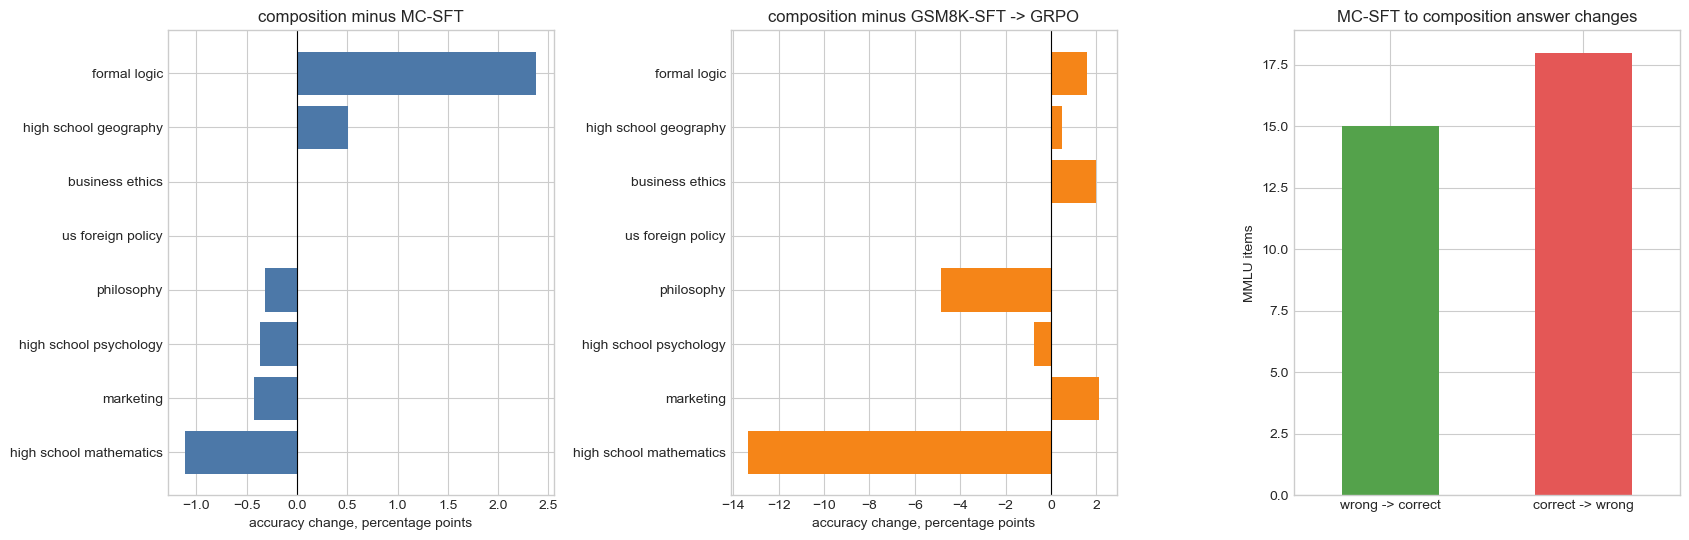

In [5]:
composition = RUNS['MC-SFT -> GRPO']
parent = RUNS['MC-SFT']
pipeline = RUNS['GSM8K-SFT -> GRPO']
subjects = list(composition['eval']['per_subject_acc'])
subject_tbl = pd.DataFrame({
    'subject': subjects,
    'minus MC-SFT': [
        composition['eval']['per_subject_acc'][subject] - parent['eval']['per_subject_acc'][subject]
        for subject in subjects
    ],
    'minus GSM8K-SFT -> GRPO': [
        composition['eval']['per_subject_acc'][subject] - pipeline['eval']['per_subject_acc'][subject]
        for subject in subjects
    ],
}).sort_values('minus MC-SFT')

parent_rows, composition_rows = align_pred_rows(parent['preds'], composition['preds'])
paired_counts = pd.Series({
    'wrong -> correct': sum(not a['correct'] and b['correct'] for a, b in zip(parent_rows, composition_rows)),
    'correct -> wrong': sum(a['correct'] and not b['correct'] for a, b in zip(parent_rows, composition_rows)),
    'correct in both': sum(a['correct'] and b['correct'] for a, b in zip(parent_rows, composition_rows)),
    'wrong in both': sum(not a['correct'] and not b['correct'] for a, b in zip(parent_rows, composition_rows)),
})

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
y = np.arange(len(subject_tbl))
axes[0].barh(y, subject_tbl['minus MC-SFT'] * 100, color='#4C78A8')
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_yticks(y)
axes[0].set_yticklabels(subject_tbl['subject'].str.replace('_', ' '))
axes[0].set_xlabel('accuracy change, percentage points')
axes[0].set_title('composition minus MC-SFT')

axes[1].barh(y, subject_tbl['minus GSM8K-SFT -> GRPO'] * 100, color='#F58518')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_yticks(y)
axes[1].set_yticklabels(subject_tbl['subject'].str.replace('_', ' '))
axes[1].set_xlabel('accuracy change, percentage points')
axes[1].set_title('composition minus GSM8K-SFT -> GRPO')

paired_counts[['wrong -> correct', 'correct -> wrong']].plot.bar(
    ax=axes[2], color=['#54A24B', '#E45756'], rot=0
)
axes[2].set_ylabel('MMLU items')
axes[2].set_title('MC-SFT to composition answer changes')
fig.tight_layout()
save(fig, 'fig04_seed2_subject_and_item_changes')
plt.show()

## Exact values

In [6]:
status_tbl.to_csv(FIG / 'run_outcomes.csv')
endpoint_tbl.to_csv(FIG / 'seed2_endpoints.csv', index=False)
subject_tbl.to_csv(FIG / 'seed2_subject_changes.csv', index=False)
display(subject_tbl.set_index('subject').round(4))
display(paired_counts.to_frame('items'))

,minus MC-SFT,minus GSM8K-SFT -> GRPO
subject,,
high_school_mathematics,-0.0111,-0.1333
marketing,-0.0043,0.0214
high_school_psychology,-0.0037,-0.0073
philosophy,-0.0032,-0.0482
us_foreign_policy,0.0000,0.0000
business_ethics,0.0000,0.0200
high_school_geography,0.0051,0.0051
formal_logic,0.0238,0.0159


,items
wrong -> correct,15
correct -> wrong,18
correct in both,1460
wrong in both,391
